<a href="https://colab.research.google.com/github/erumfatimanooranibscit2025-collab/Stock-Trend-Prediction-LSTM/blob/main/Stock_Trend_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
!pip install yfinance

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")

All libraries imported successfully!


In [53]:
ticker = "RELIANCE.NS"

data = yf.download(
    ticker,
    start="2018-01-01",
    end="2026-09-20",
    auto_adjust=False
)

data.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,,
2018-01-01,400.015350,415.907104,421.827393,414.878479,421.827393,9453202
2018-01-02,400.630859,416.547119,420.387329,414.375580,417.392883,9499419
2018-01-03,402.235779,418.215790,423.336060,417.415741,422.878876,13507800
2018-01-04,404.654144,420.730194,421.415955,418.627228,419.747284,9008932
2018-01-05,405.951202,422.078827,423.747498,420.707336,421.415955,7441284


In [54]:
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data[["Open", "High", "Low", "Close", "Volume"]]

data = data.dropna()

print("Number of rows:", len(data))
print()
print(data.head())

Number of rows: 2157

Price             Open        High         Low       Close    Volume
Date                                                                
2018-01-01  421.827393  421.827393  414.878479  415.907104   9453202
2018-01-02  417.392883  420.387329  414.375580  416.547119   9499419
2018-01-03  422.878876  423.336060  417.415741  418.215790  13507800
2018-01-04  419.747284  421.415955  418.627228  420.730194   9008932
2018-01-05  421.415955  423.747498  420.707336  422.078827   7441284


In [55]:
data["Target"] = (data["Close"].shift(-1) > data["Close"]).astype(int)

data = data.iloc[:-1]

print(data[["Close", "Target"]].head(10))

Price            Close  Target
Date                          
2018-01-01  415.907104       1
2018-01-02  416.547119       1
2018-01-03  418.215790       1
2018-01-04  420.730194       1
2018-01-05  422.078827       1
2018-01-08  424.501831       1
2018-01-09  430.170685       1
2018-01-10  430.810730       0
2018-01-11  428.707764       1
2018-01-12  433.850861       1


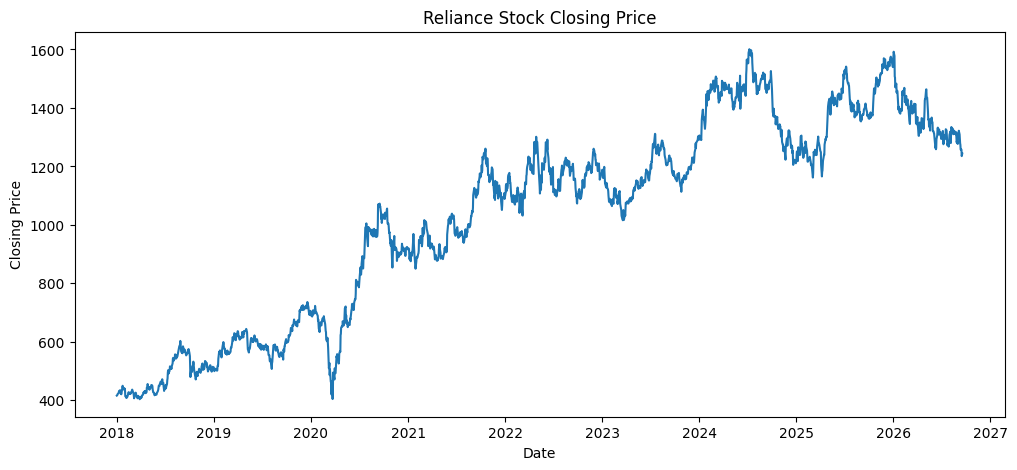

In [56]:
plt.figure(figsize=(12,5))

plt.plot(data.index, data["Close"])

plt.title("Reliance Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.show()

In [57]:
features = ["Open", "High", "Low", "Close", "Volume"]

X_data = data[features]
y_data = data["Target"]

print("Features used:")
print(features)

Features used:
['Open', 'High', 'Low', 'Close', 'Volume']


In [58]:
split = int(len(data) * 0.80)

train_data = data.iloc[:split]
test_data = data.iloc[split:]

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

Training rows: 1724
Testing rows: 432


In [59]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data[features])
test_scaled = scaler.transform(test_data[features])

print("Data successfully scaled!")

Data successfully scaled!


In [60]:
lookback = 60

X_train = []
y_train = []

for i in range(lookback, len(train_scaled)):
    X_train.append(train_scaled[i-lookback:i])
    y_train.append(train_data["Target"].iloc[i])

X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1664, 60, 5)
y_train shape: (1664,)


In [61]:
combined_features = np.vstack([
    train_scaled[-lookback:],
    test_scaled
])

X_test = []
y_test = []

for i in range(lookback, len(combined_features)):
    X_test.append(combined_features[i-lookback:i])
    y_test.append(test_data["Target"].iloc[i-lookback])

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (432, 60, 5)
y_test shape: (432,)


In [62]:
model = Sequential()

model.add(
    LSTM(
        64,
        return_sequences=True,
        input_shape=(60, 5)
    )
)

model.add(Dropout(0.2))

model.add(
    LSTM(32)
)

model.add(Dropout(0.2))

model.add(Dense(16, activation="relu"))

model.add(Dense(1, activation="sigmoid"))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 60, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [63]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.10,
    shuffle=False,
    callbacks=[early_stop]
)

Epoch 1/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 19s 202ms/step - accuracy: 0.4883 - loss: 0.6950 - val_accuracy: 0.4910 - val_loss: 0.6934
Epoch 2/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 138ms/step - accuracy: 0.5190 - loss: 0.6938 - val_accuracy: 0.5090 - val_loss: 0.6931
Epoch 3/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 155ms/step - accuracy: 0.5190 - loss: 0.6926 - val_accuracy: 0.5090 - val_loss: 0.6930
Epoch 4/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.5197 - loss: 0.6929 - val_accuracy: 0.5090 - val_loss: 0.6931
Epoch 5/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.5184 - loss: 0.6925 - val_accuracy: 0.5090 - val_loss: 0.6930
Epoch 6/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.5170 - loss: 0.6933 - val_accuracy: 0.5090 - val_loss: 0.6930
Epoch 7/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.5204 - loss: 0.6928 - val_accuracy: 0.5090 - val_loss: 0.6932
Epoch 8/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.5204 - loss: 0.6922 - val_accuracy: 0.5090

In [64]:
predicted_probability = model.predict(X_test)

predicted = (predicted_probability >= 0.5).astype(int).flatten()

print("Predictions completed!")

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step
Predictions completed!


In [65]:
accuracy = accuracy_score(y_test, predicted)
precision = precision_score(y_test, predicted)
recall = recall_score(y_test, predicted)
f1 = f1_score(y_test, predicted)

print("MODEL RESULTS")
print("-----------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

MODEL RESULTS
-----------------------
Accuracy : 48.84 %
Precision: 48.84 %
Recall   : 100.0 %
F1 Score : 65.63 %


[[  0 221]
 [  0 211]]


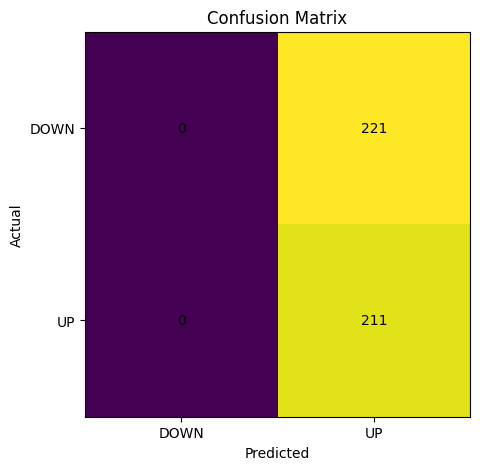

In [66]:
cm = confusion_matrix(y_test, predicted)

print(cm)

plt.figure(figsize=(6,5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["DOWN", "UP"])
plt.yticks([0, 1], ["DOWN", "UP"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

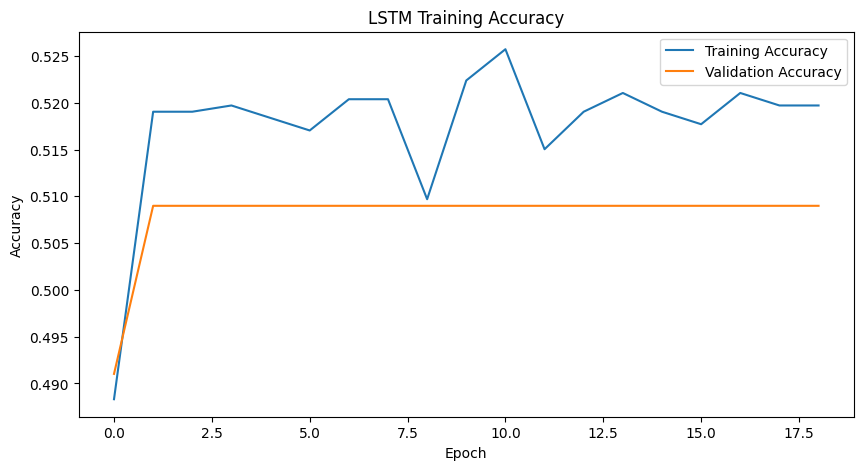

In [67]:
plt.figure(figsize=(10,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

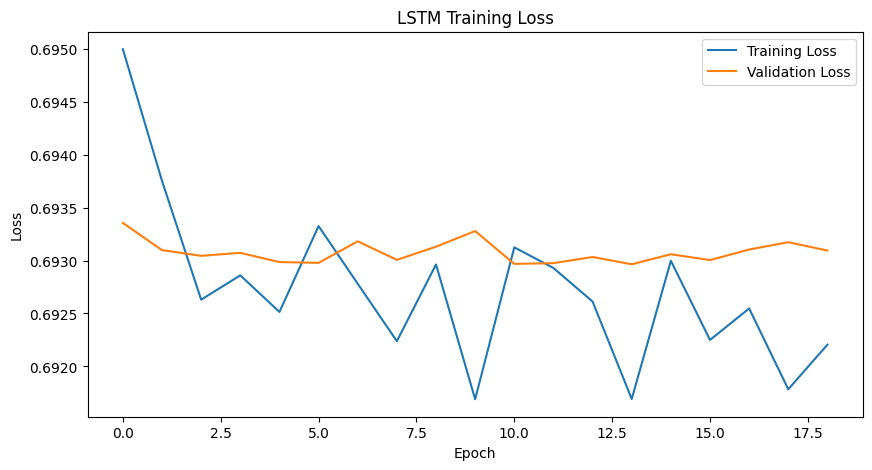

In [68]:
plt.figure(figsize=(10,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [69]:
latest_60_days = data[features].tail(60)

latest_scaled = scaler.transform(latest_60_days)

latest_scaled = latest_scaled.reshape(1, 60, 5)

prediction_probability = model.predict(latest_scaled)[0][0]

if prediction_probability >= 0.5:
    prediction = "UP 📈"
else:
    prediction = "DOWN 📉"

print("================================")
print("       STOCK TREND PREDICTION")
print("================================")

print("Stock: RELIANCE")
print("Prediction:", prediction)

print(
    "Probability of UP:",
    round(float(prediction_probability) * 100, 2),
    "%"
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
       STOCK TREND PREDICTION
Stock: RELIANCE
Prediction: UP 📈
Probability of UP: 51.2 %


In [70]:
y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print("Predictions generated successfully!")

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
Predictions generated successfully!


In [71]:
actual = np.array(y_test).flatten()

comparison = pd.DataFrame({
    "Actual Trend": actual[:len(y_pred)],
    "Predicted Trend": y_pred
})

comparison["Actual Trend"] = comparison["Actual Trend"].map({
    0: "DOWN",
    1: "UP"
})

comparison["Predicted Trend"] = comparison["Predicted Trend"].map({
    0: "DOWN",
    1: "UP"
})

comparison["Result"] = np.where(
    comparison["Actual Trend"] == comparison["Predicted Trend"],
    "Correct",
    "Wrong"
)

print("Actual vs Predicted Stock Trend:")
display(comparison.head(40))

Actual vs Predicted Stock Trend:


,Actual Trend,Predicted Trend,Result
0,DOWN,UP,Wrong
1,UP,UP,Correct
2,UP,UP,Correct
3,UP,UP,Correct
4,UP,UP,Correct
5,DOWN,UP,Wrong
6,UP,UP,Correct
7,UP,UP,Correct
8,DOWN,UP,Wrong
9,DOWN,UP,Wrong


In [72]:
correct = (actual == y_pred).sum()
total = len(y_pred)

accuracy = (correct / total) * 100

print("Correct predictions:", correct)
print("Total predictions:", total)
print("Overall Accuracy:", round(accuracy, 2), "%")

Correct predictions: 211
Total predictions: 432
Overall Accuracy: 48.84 %


In [73]:
#BACKEND
!pip install -q gradio yfinance plotly

import sqlite3
from datetime import datetime
import yfinance as yf
import pandas as pd
import numpy as np
import plotly.graph_objects as go

db = sqlite3.connect("stock_prediction.db", check_same_thread=False)

cursor = db.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS stock_data (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    ticker TEXT,
    date TEXT,
    open REAL,
    high REAL,
    low REAL,
    close REAL,
    volume REAL
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS predictions (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    ticker TEXT,
    date_time TEXT,
    latest_price REAL,
    prediction TEXT,
    up_probability REAL,
    down_probability REAL
)
""")

db.commit()


stock_map = {
    "reliance": "RELIANCE.NS",
    "reliance industries": "RELIANCE.NS",
    "hdfc": "HDFCBANK.NS",
    "hdfc bank": "HDFCBANK.NS",
    "hdfcbank": "HDFCBANK.NS",
    "tcs": "TCS.NS",
    "infosys": "INFY.NS",
    "infy": "INFY.NS",
    "icici": "ICICIBANK.NS",
    "icici bank": "ICICIBANK.NS",
    "sbi": "SBIN.NS",
    "state bank of india": "SBIN.NS",
    "itc": "ITC.NS",
    "l&t": "LT.NS",
    "lt": "LT.NS"
}


def get_ticker(stock_name):

    name = stock_name.strip().lower()

    if name in stock_map:
        return stock_map[name]

    if name.endswith(".ns"):
        return name.upper()

    return name.upper() + ".NS"


def get_stock_data(ticker):

    stock_data = yf.download(
        ticker,
        period="1y",
        auto_adjust=False,
        progress=False
    )

    if isinstance(stock_data.columns, pd.MultiIndex):
        stock_data.columns = stock_data.columns.get_level_values(0)

    stock_data = stock_data[
        ["Open", "High", "Low", "Close", "Volume"]
    ].dropna()

    return stock_data


def save_stock_data(ticker, stock_data):

    for index, row in stock_data.iterrows():

        cursor.execute(
            """
            INSERT INTO stock_data
            (ticker, date, open, high, low, close, volume)
            VALUES (?, ?, ?, ?, ?, ?, ?)
            """,
            (
                ticker,
                str(index.date()),
                float(row["Open"]),
                float(row["High"]),
                float(row["Low"]),
                float(row["Close"]),
                float(row["Volume"])
            )
        )

    db.commit()


def save_prediction(
    ticker,
    latest_price,
    prediction,
    up_probability,
    down_probability
):

    cursor.execute(
        """
        INSERT INTO predictions
        (ticker, date_time, latest_price, prediction,
         up_probability, down_probability)
        VALUES (?, ?, ?, ?, ?, ?)
        """,
        (
            ticker,
            datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            latest_price,
            prediction,
            up_probability,
            down_probability
        )
    )

    db.commit()


def predict_stock(stock_name):

    if not stock_name:
        return None, None, None

    try:

        ticker = get_ticker(stock_name)

        stock_data = get_stock_data(ticker)

        if len(stock_data) < 60:
            return (
                "Not enough data available.",
                None,
                None
            )

        save_stock_data(ticker, stock_data)

        latest_data = stock_data[features].tail(60)

        latest_scaled = scaler.transform(latest_data)

        latest_sequence = np.array([latest_scaled])

        probability = float(
            model.predict(
                latest_sequence,
                verbose=0
            )[0][0]
        )

        if probability >= 0.5:
            prediction = "UP"
        else:
            prediction = "DOWN"

        up_probability = probability * 100
        down_probability = (1 - probability) * 100

        latest_price = float(
            stock_data["Close"].iloc[-1]
        )

        save_prediction(
            ticker,
            latest_price,
            prediction,
            up_probability,
            down_probability
        )

        chart_data = stock_data.tail(126)

        fig = go.Figure()

        fig.add_trace(
            go.Scatter(
                x=chart_data.index,
                y=chart_data["Close"],
                mode="lines",
                name="Closing Price"
            )
        )

        fig.update_layout(
            title=f"{ticker} Stock Price",
            xaxis_title="Date",
            yaxis_title="Price",
            template="plotly_white",
            height=430,
            hovermode="x unified"
        )

        result = f"""
## {ticker}

### Prediction: {prediction}

**UP Probability:** {up_probability:.2f}%

**DOWN Probability:** {down_probability:.2f}%

**Latest Price:** ₹{latest_price:.2f}

**Model:** LSTM

**Input:** Previous 60 Trading Days

**Features:** Open, High, Low, Close, Volume
"""

        return result, fig, f"Prediction saved for {ticker}"

    except Exception as e:

        return (
            f"Error: {str(e)}",
            None,
            "Please check the stock name."
        )

In [74]:
!pip install -q gradio yfinance plotly

In [75]:
import gradio as gr
import yfinance as yf
import numpy as np
import pandas as pd
import plotly.graph_objects as go

stock_map = {
    "reliance": "RELIANCE.NS",
    "reliance industries": "RELIANCE.NS",
    "hdfc": "HDFCBANK.NS",
    "hdfc bank": "HDFCBANK.NS",
    "hdfcbank": "HDFCBANK.NS",
    "tcs": "TCS.NS",
    "infosys": "INFY.NS",
    "infy": "INFY.NS",
    "icici": "ICICIBANK.NS",
    "icici bank": "ICICIBANK.NS",
    "sbi": "SBIN.NS",
    "state bank of india": "SBIN.NS",
    "itc": "ITC.NS",
    "l&t": "LT.NS",
    "lt": "LT.NS"
}

def predict_stock(stock_name):

    if not stock_name:
        return "⚠️ Please enter a stock name.", None

    user_input = stock_name.strip().lower()

    if user_input in stock_map:
        ticker_symbol = stock_map[user_input]
    elif user_input.endswith(".ns"):
        ticker_symbol = user_input.upper()
    else:
        ticker_symbol = user_input.upper() + ".NS"

    try:
        stock_data = yf.download(
            ticker_symbol,
            period="1y",
            auto_adjust=False,
            progress=False
        )

        if isinstance(stock_data.columns, pd.MultiIndex):
            stock_data.columns = stock_data.columns.get_level_values(0)

        stock_data = stock_data[
            ["Open", "High", "Low", "Close", "Volume"]
        ].dropna()

        if len(stock_data) < 60:
            return f"❌ Not enough data available for {ticker_symbol}", None

        latest_data = stock_data[features].tail(60)
        latest_scaled = scaler.transform(latest_data)
        latest_sequence = np.array([latest_scaled])

        probability = model.predict(
            latest_sequence,
            verbose=0
        )[0][0]

        if probability >= 0.5:
            prediction = "UP"
        else:
            prediction = "DOWN"

        up_probability = probability * 100
        down_probability = (1 - probability) * 100

        latest_price = float(
            stock_data["Close"].iloc[-1]
        )

        chart_data = stock_data.tail(126)

        fig = go.Figure()

        fig.add_trace(
            go.Scatter(
                x=chart_data.index,
                y=chart_data["Close"],
                mode="lines",
                name="Closing Price"
            )
        )

        fig.update_layout(
            title=f"{ticker_symbol} Stock Price",
            xaxis_title="Date",
            yaxis_title="Closing Price",
            template="plotly_dark",
            height=450,
            hovermode="x unified"
        )

        result = f"""
# 📊 Stock Trend Prediction

## {ticker_symbol}

### Prediction: **{prediction}**

---

### 📈 UP Probability
# **{up_probability:.2f}%**

### 📉 DOWN Probability
# **{down_probability:.2f}%**

---

| Information | Value |
|---|---|
| **Latest Close** | ₹{latest_price:.2f} |
| **Model** | LSTM |
| **Input Data** | Previous 60 Trading Days |
| **Features** | Open, High, Low, Close, Volume |
| **Prediction Type** | Binary Classification |

---

### 🧠 How it works

The model uses the **previous 60 trading days** of OHLCV data and predicts whether the next short-term trend will be **UP or DOWN**.

> ⚠️ This prediction is based only on historical market patterns.
> It is not guaranteed and should not be treated as financial advice.
"""

        return result, fig

    except Exception as e:
        return f"""
# ❌ Error

Could not process **{ticker_symbol}**.

Please check the stock name or ticker.

Example:
- HDFC Bank
- Reliance
- TCS
- Infosys
- ICICI Bank
- SBI

Error: `{str(e)}`
""", None


css = """
body {
    background: #0f172a;
}

.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

#title {
    text-align: center;
}

#search_box {
    border-radius: 15px;
}

button {
    border-radius: 12px !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(),
    css=css,
    title="Stock Trend Prediction"
) as dashboard:

    gr.Markdown(
        """
        # 📈 STOCK TREND PREDICTION
        ### 🧠 LSTM Deep Learning Dashboard

        Enter a stock name below to see its **price graph and predicted trend probability**.
        """,
        elem_id="title"
    )

    gr.Markdown(
        """
        **Model:** LSTM
        **Input:** Previous 60 Trading Days
        **Features:** Open • High • Low • Close • Volume
        **Output:** UP / DOWN
        """
    )

    with gr.Row():

        stock_input = gr.Textbox(
            label="🔎 Enter Stock Name",
            placeholder="Example: HDFC Bank",
            elem_id="search_box",
            scale=4
        )

        predict_button = gr.Button(
            "🚀 Predict Trend",
            variant="primary",
            scale=1
        )

    gr.Markdown(
        """
        ### Try these:
        `Reliance` • `HDFC Bank` • `TCS` • `Infosys` • `ICICI Bank` • `SBI`
        """
    )

    result_output = gr.Markdown()

    stock_graph = gr.Plot(
        label="📈 Stock Price Graph"
    )

    gr.Markdown(
        """
        ---
        ### ⚠️ Disclaimer
        This dashboard is a **Deep Learning project demonstration**.
        Predictions are based on historical OHLCV patterns and are not guaranteed.
        """
    )

    predict_button.click(
        fn=predict_stock,
        inputs=stock_input,
        outputs=[result_output, stock_graph]
    )

    stock_input.submit(
        fn=predict_stock,
        inputs=stock_input,
        outputs=[result_output, stock_graph]
    )

dashboard.launch(share=True)

/tmp/ipykernel_1408/2949808703.py:180: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c45dbfe2d428c28c6b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
